Upload prophet_forecasts.csv and the LightGBM forecasts csv


Saving lightgbm_forecasts.csv to lightgbm_forecasts.csv
Saving prophet_forecasts.csv to prophet_forecasts (1).csv
Using: prophet_forecasts (1).csv | lightgbm_forecasts.csv
Holdout weeks matched per category: {'FOODS': 12, 'HOBBIES': 12, 'HOUSEHOLD': 12}

    model       level     MAE    RMSE  WMAPE  Bias%
 prophet       FOODS 21936.0 24125.5 0.1115  11.15
 prophet     HOBBIES  2387.0  2512.5 0.0876  -8.76
 prophet   HOUSEHOLD  3189.0  3607.7 0.0451  -3.61
 prophet ALL (total) 17237.0 20004.0 0.0585   5.77
lightgbm       FOODS 18624.6 19134.4 0.0946   9.46
lightgbm     HOBBIES   904.5  1082.1 0.0332  -2.40
lightgbm   HOUSEHOLD  1827.3  2326.9 0.0259   1.20
lightgbm ALL (total) 18815.3 19311.5 0.0638   6.38

WMAPE by level (lower is better):
 model        lightgbm  prophet    winner
level                                   
ALL (total)    0.0638   0.0585   prophet
FOODS          0.0946   0.1115  lightgbm
HOBBIES        0.0332   0.0876  lightgbm
HOUSEHOLD      0.0259   0.0451  lightgbm

Li

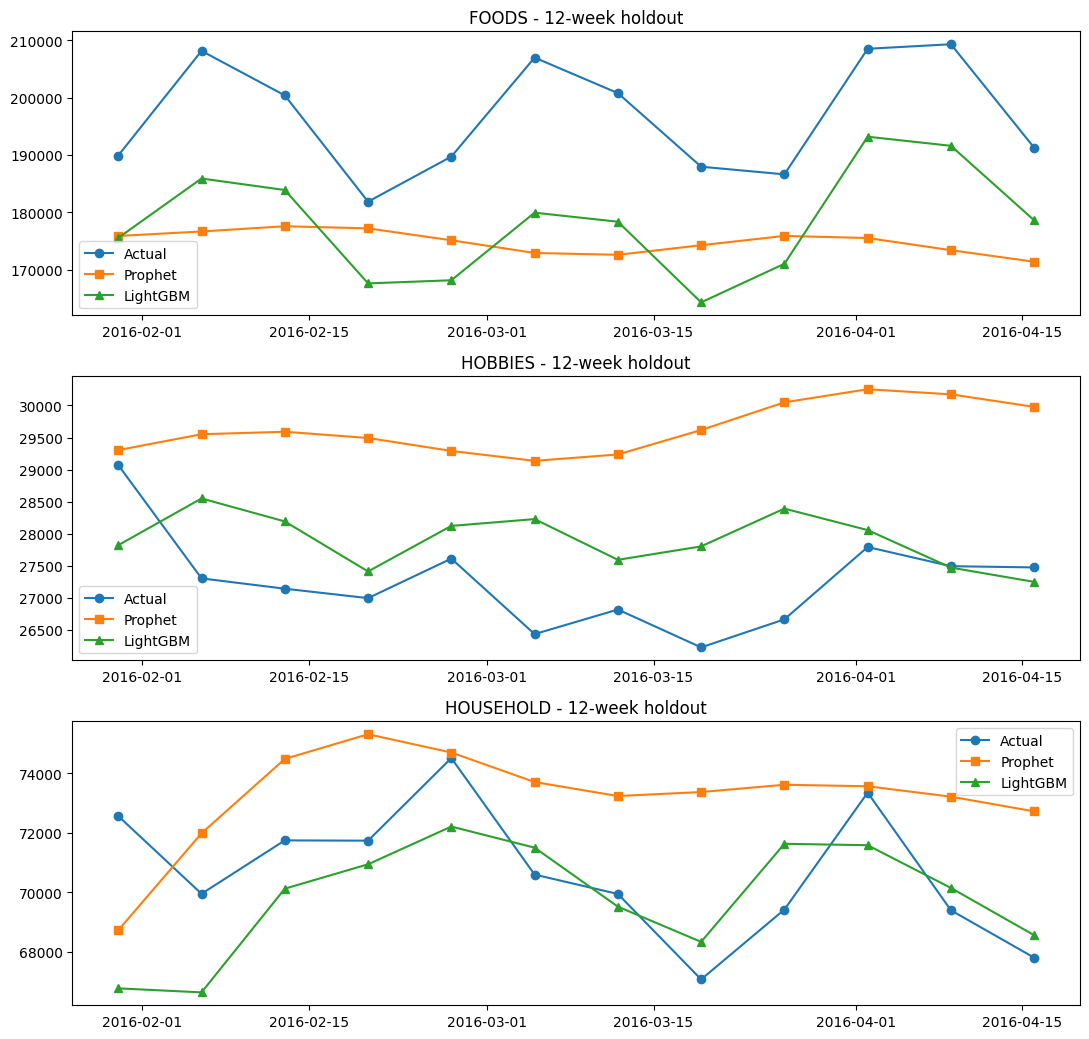


Saved model_comparison.csv, model_comparison.png, model_evaluation.md


In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Upload prophet_forecasts.csv and the LightGBM forecasts csv")
uploaded = files.upload()
prophet_file = [f for f in uploaded if "prophet" in f.lower()][0]
lgb_file = [f for f in uploaded if "lightgbm" in f.lower() and f.endswith(".csv")][0]
print("Using:", prophet_file, "|", lgb_file)

prophet = pd.read_csv(prophet_file, parse_dates=["ds"])
lgbm = pd.read_csv(lgb_file, parse_dates=["week_start"])

# ---- 1. Put both models on the same footing: category x week, 12-week holdout ----
lgb_cat = (lgbm.groupby(["cat_id", "week_start"], as_index=False)[["y", "pred"]].sum()
           .rename(columns={"week_start": "ds", "y": "actual", "pred": "lightgbm"}))
pro = prophet.rename(columns={"yhat": "prophet"})[["ds", "cat_id", "prophet"]]
comp = lgb_cat.merge(pro, on=["cat_id", "ds"], how="inner")
print("Holdout weeks matched per category:", comp.groupby("cat_id").size().to_dict())

# ---- 2. Metrics ----
def metrics(d, col):
    err = d["actual"] - d[col]
    return {
        "MAE": round(np.mean(np.abs(err)), 1),
        "RMSE": round(np.sqrt(np.mean(err ** 2)), 1),
        "WMAPE": round(np.sum(np.abs(err)) / np.sum(d["actual"]), 4),
        "Bias%": round(err.sum() / d["actual"].sum() * 100, 2),  # + = under-forecast
    }

rows = []
total = comp.groupby("ds", as_index=False)[["actual", "prophet", "lightgbm"]].sum()
for model in ["prophet", "lightgbm"]:
    for cat, d in comp.groupby("cat_id"):
        rows.append({"model": model, "level": cat, **metrics(d, model)})
    rows.append({"model": model, "level": "ALL (total)", **metrics(total, model)})
results = pd.DataFrame(rows)
print("\n", results.to_string(index=False))

pivot = results.pivot(index="level", columns="model", values="WMAPE")
pivot["winner"] = pivot[["prophet", "lightgbm"]].idxmin(axis=1)
print("\nWMAPE by level (lower is better):\n", pivot)

# LightGBM at its native, more granular level
sd = lgbm["y"] - lgbm["pred"]
print(f"\nLightGBM store x dept level WMAPE: {np.sum(np.abs(sd)) / np.sum(lgbm['y']):.4f}")

# ---- 3. Plot ----
cats = sorted(comp["cat_id"].unique())
fig, axes = plt.subplots(len(cats), 1, figsize=(11, 3.5 * len(cats)))
for ax, cat in zip(axes, cats):
    d = comp[comp["cat_id"] == cat].sort_values("ds")
    ax.plot(d["ds"], d["actual"], marker="o", label="Actual")
    ax.plot(d["ds"], d["prophet"], marker="s", label="Prophet")
    ax.plot(d["ds"], d["lightgbm"], marker="^", label="LightGBM")
    ax.set_title(f"{cat} - 12-week holdout")
    ax.legend()
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- 4. Save outputs ----
results.to_csv("model_comparison.csv", index=False)

def to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

with open("model_evaluation.md", "w") as f:
    f.write("# Model Evaluation: Prophet vs LightGBM\n\n")
    f.write("12-week holdout, compared at category level (LightGBM store x dept forecasts summed to category).\n\n")
    f.write("## Metrics\n\n" + to_md(results) + "\n\n")
    f.write("## WMAPE winner by level\n\n" + to_md(pivot.reset_index()) + "\n")
print("\nSaved model_comparison.csv, model_comparison.png, model_evaluation.md")